<a href="https://colab.research.google.com/github/diogenesjusto/FIAP/blob/master/MBAIA/18DTSR/18DTSR_Aula3_Trabalho.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [77]:
# 0. Carga de bibliotecas
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

In [67]:
# 1. Carga de dados
df = pd.read_csv("https://raw.githubusercontent.com/diogenesjusto/FIAP/refs/heads/master/dados/credit_features_formatado.csv")

/tmp/ipykernel_4800/438629623.py:2: DtypeWarning: Columns (52,53) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("https://raw.githubusercontent.com/diogenesjusto/FIAP/refs/heads/master/dados/credit_features_formatado.csv")


In [68]:
# 2. Transformações de dados
dummies_sexo = pd.get_dummies(df['SEXO'])
dummies_sexo
df['Dummy_F'] = dummies_sexo['F']

In [69]:
# 3. Separação de treino e teste
x_treino, x_teste, y_treino, y_teste = train_test_split(df[['Dummy_F', 'ESTADO_CIVIL', 'RENDA_PESSOAL_MENSAL']], df['ROTULO_ALVO_MAU=1'], test_size=0.3, random_state=1)

In [84]:
# 4.1 Modelo de Árvore de Decisão
# mod = DecisionTreeClassifier()
# 4.2 Modelo regressão logística
# mod = LogisticRegression()
# 4.3 Modelo Random Forest
modRF = RandomForestClassifier()

modRF.fit(x_treino, y_treino)

RandomForestClassifier()

1a Técnica de análise de importância de features: aplicável a regressões, faremos a análise dos coeficientes


In [86]:
# Vamos analisar os coeficientes da regressão
#mod.coef_

2a. Análise de importância de variávies utilizando a técnica "decision split", implementada no RandomForest

In [85]:
modRF.feature_importances_

array([0.0036946 , 0.028316  , 0.96798941])

<Axes: >

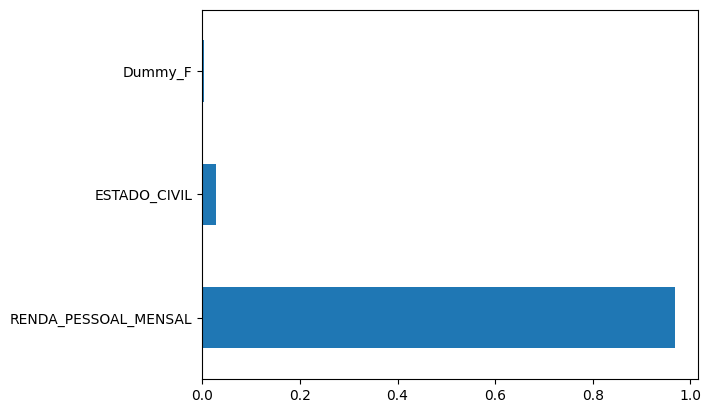

In [88]:
# visualização gráfica
feature_importance = pd.Series(modRF.feature_importances_, index=x_treino.columns)
feature_importance.nlargest(6).plot(kind='barh')

3a. Análise de importância de features com base em permutações

<BarContainer object of 3 artists>

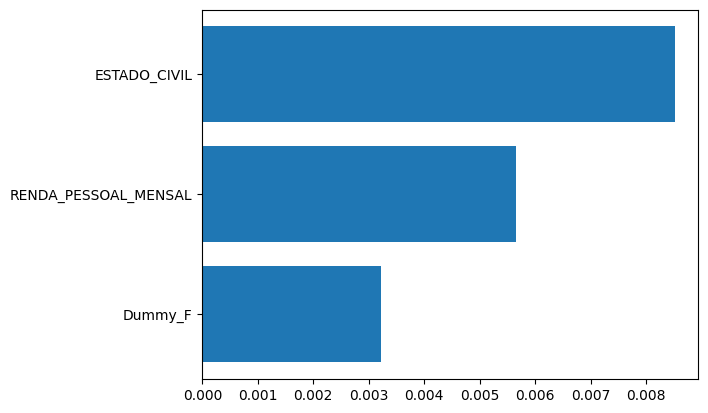

In [94]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# podemos utilizar a permutação com QUALQUER ALGORITMO, regressão linear, logística, árvores de decisão, randomforest, etc...
perm_importance = permutation_importance(modRF, x_teste, y_teste, n_repeats=100 )

ordem_idx = perm_importance.importances_mean.argsort()

plt.barh(x_teste.columns[ordem_idx], perm_importance.importances_mean[ordem_idx])


In [71]:
# 5. Análise do Erro de Previsão
y_prev = mod.predict(x_teste)

In [72]:
# 6. Erros em classificadores
# Matriz de Confusão
pd.crosstab(y_prev, y_teste, margins=True)

ROTULO_ALVO_MAU=1,0,1,All
row_0,,,
0,10322,3610,13932
1,756,312,1068
All,11078,3922,15000


In [73]:
# 7. Métricas de análise de erro de classificadores
print( accuracy_score(y_prev, y_teste) )
print( precision_score(y_prev, y_teste) )
print( recall_score(y_prev, y_teste) )


0.7089333333333333
0.07955124936257012
0.29213483146067415
